# 04 — Evaluasi dan Hipotesis

Evaluasi akhir pada data uji, dijalankan **sekali**. Semua hyperparameter sudah dibekukan di notebook 03 (`results/cv_results.csv`), dan model terbaik per skenario dipilih dari validasi silang, bukan dari data uji. Notebook ini tidak mengubah keputusan apa pun berdasarkan hasil uji.

Data uji: 115 foto asli (10–11 per kelas) dari `origin_id` yang tidak pernah muncul di data latih. Satu foto uji setara sekitar 0,87 poin persentase akurasi.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
t0 = time.time()

import ast
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.features import extract_table, scenario_columns
from src.evaluate import summarize, plot_confusion, compare

FIG_DIR = config.FIGURES_DIR / "04_evaluasi"
FIG_DIR.mkdir(parents=True, exist_ok=True)
split = pd.read_csv(config.RESULTS_DIR / "split.csv")
cvres = pd.read_csv(config.RESULTS_DIR / "cv_results.csv")
cvres["best_params"] = cvres["best_params"].apply(ast.literal_eval)
feats_tr = pd.read_csv(config.FEATURES_DIR / "features_train.csv")
dA = feats_tr[feats_tr["aug_type"] == "original"].reset_index(drop=True)
SCEN = scenario_columns(feats_tr.columns)
print(f"Latih (Opsi A): {len(dA)} foto asli; model dibekukan: {len(cvres)}")

Latih (Opsi A): 457 foto asli; model dibekukan: 12


## 1. Ekstraksi fitur data uji

In [2]:
test = split[split["split"] == "test"].reset_index(drop=True)
assert set(test["aug_type"]) == {"original"}
assert set(test["origin_id"]).isdisjoint(dA["origin_id"])
cache = config.FEATURES_DIR / "features_test.csv"
if cache.exists() and pd.read_csv(cache, usecols=["filename"])["filename"].tolist() == test["filename"].tolist():
    feats_te = pd.read_csv(cache)
else:
    feats_te = extract_table(test[["filename", "label", "origin_id", "aug_type", "split"]])
    feats_te.to_csv(cache, index=False)
print(f"{len(feats_te)} foto uji; per kelas: {feats_te['label'].value_counts().min()}–{feats_te['label'].value_counts().max()}")

115 foto uji; per kelas: 10–11


## 2. Latih ulang dengan hyperparameter beku, lalu uji

Tiap model dilatih ulang pada seluruh foto asli latih (457) memakai `best_params` dari validasi silang, lalu memprediksi data uji satu kali.

In [3]:
rows, preds, models = [], {}, {}
for _, r in cvres.iterrows():
    cols = SCEN[r["scenario"]]
    params = {f"svc__{k}": v for k, v in r["best_params"].items()}
    model = Pipeline([("scaler", StandardScaler()),
                      ("svc", SVC(kernel=r["kernel"], class_weight="balanced"))]).set_params(**params)
    model.fit(dA[cols].to_numpy(), dA["label"].to_numpy())
    pred = model.predict(feats_te[cols].to_numpy())
    preds[(r["scenario"], r["kernel"])] = pred
    models[(r["scenario"], r["kernel"])] = model
    rows.append({"scenario": r["scenario"], "kernel": r["kernel"], "best_params": r["best_params"],
                 **summarize(feats_te["label"], pred)})
test_res = pd.DataFrame(rows)
test_res.to_csv(config.RESULTS_DIR / "test_results.csv", index=False)
print("Disimpan: results/test_results.csv")

Disimpan: results/test_results.csv


In [4]:
comp = cvres[["scenario", "kernel", "best_in_scenario", "f1_macro_mean", "f1_macro_std", "accuracy_mean"]].merge(
    test_res[["scenario", "kernel", "f1_macro", "accuracy"]], on=["scenario", "kernel"])
comp = comp.rename(columns={"best_in_scenario": "terbaik (CV)", "f1_macro_mean": "F1 CV", "f1_macro_std": "std F1 CV",
                            "accuracy_mean": "akurasi CV", "f1_macro": "F1 uji", "accuracy": "akurasi uji"})
comp.round(3)

,scenario,kernel,terbaik (CV),F1 CV,std F1 CV,akurasi CV,F1 uji,akurasi uji
0,S1,linear,False,0.927,0.016,0.928,0.923,0.922
1,S1,rbf,True,0.954,0.007,0.954,0.965,0.965
2,S1,poly,False,0.930,0.034,0.932,0.983,0.983
3,S2,linear,True,0.980,0.011,0.980,1.000,1.000
4,S2,rbf,False,0.973,0.027,0.974,1.000,1.000
5,S2,poly,False,0.974,0.018,0.974,1.000,1.000
6,S3,linear,False,0.916,0.004,0.915,0.916,0.922
7,S3,rbf,True,0.938,0.033,0.939,0.953,0.957
8,S3,poly,False,0.892,0.035,0.893,0.896,0.896
9,S4,linear,True,0.950,0.013,0.950,0.961,0.965


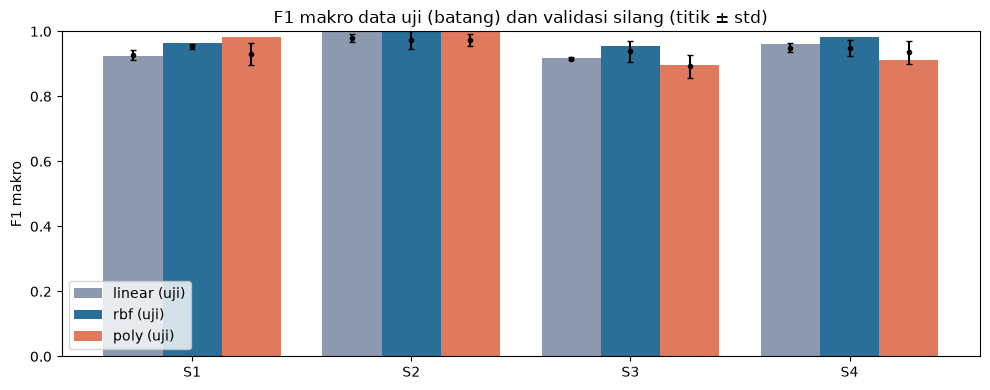

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = {"linear": "#8d99ae", "rbf": "#2a6f97", "poly": "#e07a5f"}
x = np.arange(len(SCEN))
for i, k in enumerate(["linear", "rbf", "poly"]):
    sub = comp[comp["kernel"] == k].set_index("scenario").loc[list(SCEN)]
    ax.bar(x + (i - 1) * 0.27, sub["F1 uji"], width=0.27, color=colors[k], label=f"{k} (uji)")
    ax.errorbar(x + (i - 1) * 0.27, sub["F1 CV"], yerr=sub["std F1 CV"], fmt="o", color="black", ms=3, capsize=2)
ax.set_xticks(x, list(SCEN)); ax.set_ylim(0, 1); ax.set_ylabel("F1 makro")
ax.set_title("F1 makro data uji (batang) dan validasi silang (titik ± std)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "f1_uji_vs_cv.png", dpi=150)
plt.show()

## 3. Confusion matrix model terbaik per skenario

Model terbaik per skenario adalah kernel dengan F1 makro validasi silang tertinggi (dipilih di notebook 03).

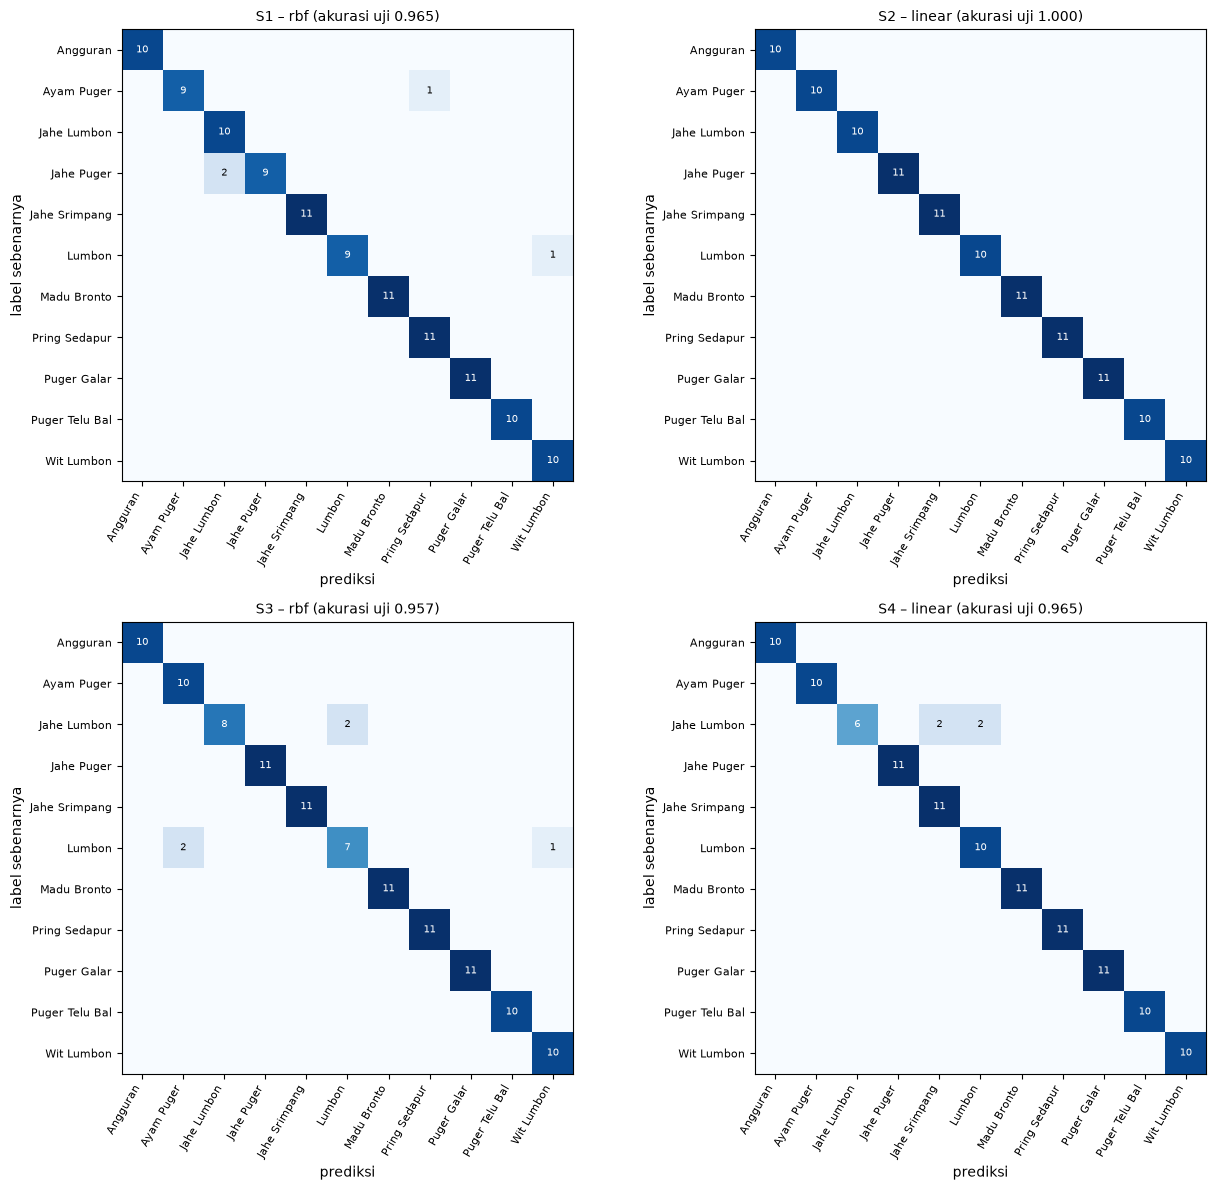

In [6]:
best = cvres[cvres["best_in_scenario"]].set_index("scenario").loc[list(SCEN)]
y_te = feats_te["label"].to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, (scen, r) in zip(axes.flat, best.iterrows()):
    acc = test_res[(test_res["scenario"] == scen) & (test_res["kernel"] == r["kernel"])]["accuracy"].iloc[0]
    plot_confusion(y_te, preds[(scen, r["kernel"])], ax, title=f"{scen} – {r['kernel']} (akurasi uji {acc:.3f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_terbaik_per_skenario.png", dpi=130)
plt.show()

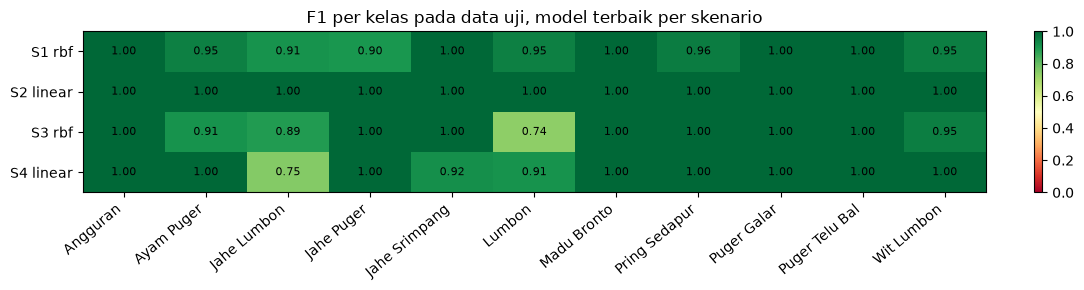

In [7]:
f1_cls = test_res.set_index(["scenario", "kernel"]).loc[[(s, best.loc[s, "kernel"]) for s in SCEN],
                                                      [f"f1_{c}" for c in config.CLASSES]]
f1_cls.columns = config.CLASSES
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(f1_cls.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(config.CLASSES)), config.CLASSES, rotation=40, ha="right")
ax.set_yticks(range(len(f1_cls)), [f"{s} {k}" for s, k in f1_cls.index])
for i in range(f1_cls.shape[0]):
    for j in range(f1_cls.shape[1]):
        ax.text(j, i, f"{f1_cls.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("F1 per kelas pada data uji, model terbaik per skenario")
fig.colorbar(im, ax=ax, fraction=0.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "f1_per_kelas_uji.png", dpi=150)
plt.show()

### Simpan model terbaik dan prediksi uji

Model terbaik secara keseluruhan dipilih dengan kriteria yang sama seperti di notebook 03: **F1 makro validasi silang tertinggi**, bukan skor data uji. Model yang disimpan adalah objek yang **sudah dilatih di sel di atas**; tidak ada training ulang. Bersama model disimpan metadata JSON (skenario, kernel, parameter, urutan kolom fitur, `IMG_SIZE`, kelas, dan versi scikit-learn), supaya `src/predict.py` bisa menyusun fitur dengan urutan yang persis sama.

Prediksi ke-12 model pada data uji juga disimpan ke `results/test_predictions.csv`. File ini menjadi acuan test: `predict_image` harus menghasilkan label yang sama untuk tiap foto uji.

In [8]:
import json, joblib, sklearn, datetime

best_row = cvres.loc[cvres["f1_macro_mean"].idxmax()]
te = lambda s, k: test_res[(test_res["scenario"] == s) & (test_res["kernel"] == k)].iloc[0]
key = (best_row["scenario"], best_row["kernel"])
best_model = models[key]
config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(best_model, config.MODELS_DIR / "best_model.joblib")
meta = {
    "scenario": key[0], "kernel": key[1], "params": best_row["best_params"],
    "selection": "highest mean f1_macro in 5-fold CV (notebook 03); not chosen on test data",
    "cv_f1_macro_mean": round(float(best_row["f1_macro_mean"]), 4),
    "cv_f1_macro_std": round(float(best_row["f1_macro_std"]), 4),
    "test_f1_macro": round(float(te(*key).f1_macro), 4),
    "feature_columns": SCEN[key[0]],
    "classes": list(best_model.classes_),
    "IMG_SIZE": config.IMG_SIZE, "CLAHE_CLIP_LIMIT": config.CLAHE_CLIP_LIMIT,
    "GLCM_LEVELS": config.GLCM_LEVELS, "GLCM_DISTANCES": config.GLCM_DISTANCES,
    "LBP": {"P": config.LBP_P, "R": config.LBP_R, "method": config.LBP_METHOD},
    "trained_on": "Option A: 457 original training photos",
    "sklearn_version": sklearn.__version__,
    "created": datetime.date.today().isoformat(),
}
(config.MODELS_DIR / "best_model.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

pred_df = feats_te[["filename", "label"]].copy()
for (s, k), p in preds.items():
    pred_df[f"pred_{s}_{k}"] = p
pred_df.to_csv(config.RESULTS_DIR / "test_predictions.csv", index=False)
print(f"Model terbaik: {key[0]} {key[1]} {best_row['best_params']} (F1 CV {best_row['f1_macro_mean']:.3f})")
print("Disimpan: models/best_model.joblib, models/best_model.json, results/test_predictions.csv")

Model terbaik: S2 linear {'C': 100} (F1 CV 0.980)
Disimpan: models/best_model.joblib, models/best_model.json, results/test_predictions.csv


## 4. Kebingungan antar-motif serumpun

Syafi'i (2024) menyebut beberapa motif Banyumasan mengambil pola dasar dari motif lain. Di sini dihitung berapa bagian kesalahan prediksi yang jatuh ke kelas **satu rumpun nama**:

- keluarga Lumbon: Jahe Lumbon, Lumbon, Wit Lumbon;
- keluarga Puger: Ayam Puger, Jahe Puger, Puger Galar, Puger Telu Bal.

Jahe Lumbon dan Jahe Puger juga sama-sama mengandung "Jahe" (bersama Jahe Srimpang), sehingga keluarga Jahe ikut dihitung.

In [9]:
FAMILIES = {
    "Lumbon": {"Jahe Lumbon", "Lumbon", "Wit Lumbon"},
    "Puger": {"Ayam Puger", "Jahe Puger", "Puger Galar", "Puger Telu Bal"},
    "Jahe": {"Jahe Lumbon", "Jahe Puger", "Jahe Srimpang"},
}

def same_family(a, b):
    return any(a in f and b in f for f in FAMILIES.values())

fam_rows = []
for scen in SCEN:
    k = best.loc[scen, "kernel"]
    pred = preds[(scen, k)]
    err = [(t, p) for t, p in zip(y_te, pred) if t != p]
    fam_rows.append({"skenario": f"{scen} {k}", "salah": len(err),
                     "salah ke rumpun sama": sum(same_family(t, p) for t, p in err)})
fam = pd.DataFrame(fam_rows)
fam["porsi rumpun sama"] = (fam["salah ke rumpun sama"] / fam["salah"].clip(lower=1)).round(2)
fam

,skenario,salah,salah ke rumpun sama,porsi rumpun sama
0,S1 rbf,4,3,0.75
1,S2 linear,0,0,0.00
2,S3 rbf,5,3,0.60
3,S4 linear,4,4,1.00


In [10]:
# Expected share if errors were spread uniformly over the 10 wrong classes
share = np.mean([sum(same_family(a, b) for b in config.CLASSES if b != a) / (len(config.CLASSES) - 1) for a in config.CLASSES])
print(f"Porsi rumpun sama jika kesalahan tersebar acak: {share:.2f}")

Porsi rumpun sama jika kesalahan tersebar acak: 0.22


In [11]:
pairs = []
for scen in SCEN:
    k = best.loc[scen, "kernel"]
    pairs += [(t, p) for t, p in zip(y_te, preds[(scen, k)]) if t != p]
top_pairs = pd.Series([f"{t} → {p}" for t, p in pairs]).value_counts().head(10)
print("Pasangan salah terbanyak (gabungan 4 model terbaik):")
print(top_pairs.to_string())

Pasangan salah terbanyak (gabungan 4 model terbaik):
Jahe Lumbon → Lumbon           4
Jahe Puger → Jahe Lumbon       2
Lumbon → Wit Lumbon            2
Lumbon → Ayam Puger            2
Jahe Lumbon → Jahe Srimpang    2
Ayam Puger → Pring Sedapur     1


## 5. Pemeriksaan validitas: apakah foto uji berasal dari kain yang sama dengan foto latih?

Split per foto asli mencegah salinan augmentasi bocor ke data uji. Namun dataset ini dipotret di satu rumah batik, sehingga satu kain fisik bisa saja difoto berkali-kali di posisi berbeda. Kalau begitu, foto uji dan foto latih bisa berasal dari **kain yang sama**, dan akurasi tinggi sebagian berarti "mengenali kain ini", bukan "mengenali motif ini pada kain baru".

Pemeriksaan ini dilakukan **setelah** evaluasi dan tidak dipakai untuk mengubah keputusan apa pun. Untuk tiap foto uji dicari foto asli latih terdekat di ruang fitur S2 (dinormalisasi dengan statistik data latih), lalu dilihat secara visual dan dari nomor urut fotonya.

In [12]:
cols = SCEN["S2"]
mu, sd = dA[cols].mean(), dA[cols].std()
A = ((feats_te[cols] - mu) / sd).to_numpy()
Bm = ((dA[cols] - mu) / sd).to_numpy()
nn = ((A[:, None, :] - Bm[None]) ** 2).sum(-1).argmin(1)
idx_of = lambda fn: int(fn.rsplit("(", 1)[1].split(")")[0])
gap = np.array([abs(idx_of(a) - idx_of(b)) for a, b in zip(feats_te["filename"], dA["filename"].iloc[nn])])
print(f"Tetangga terdekat berlabel sama: {(dA['label'].to_numpy()[nn] == y_te).mean():.3f}")
print(f"Selisih nomor foto uji vs tetangga terdekat: median {np.median(gap):.0f}, "
      f"≤ 3 pada {np.mean(gap <= 3):.0%} foto uji (nomor foto per kelas 1–52)")

Tetangga terdekat berlabel sama: 1.000
Selisih nomor foto uji vs tetangga terdekat: median 2, ≤ 3 pada 73% foto uji (nomor foto per kelas 1–52)


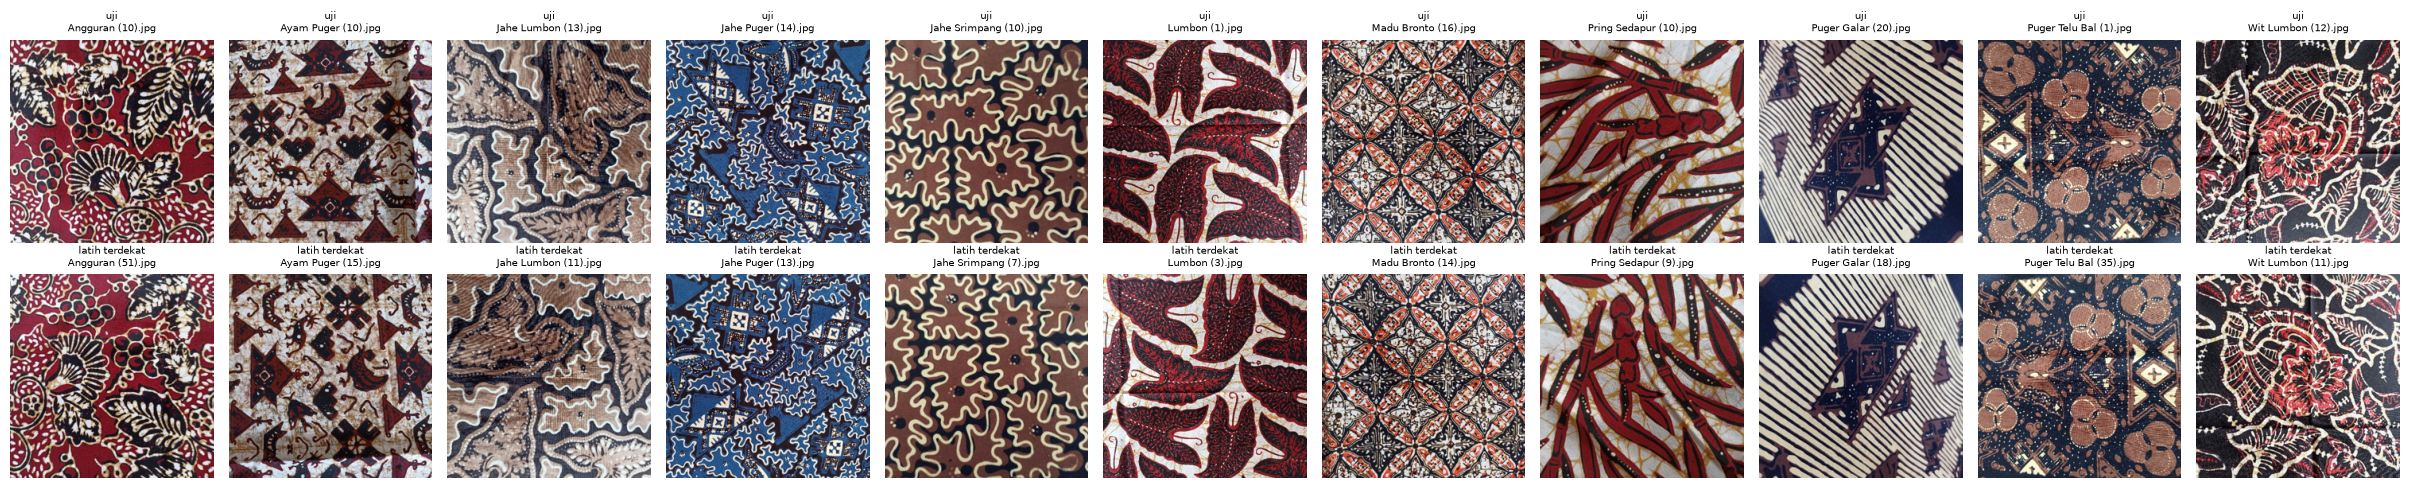

In [13]:
from PIL import Image

def thumb(fn):
    im = Image.open(config.RAW_DIR / fn).convert("RGB"); im.thumbnail((256, 256)); return im

pick = feats_te.groupby("label").head(1).index
fig, axes = plt.subplots(2, len(pick), figsize=(2.2 * len(pick), 5))
for j, i in enumerate(pick):
    for r, fn in enumerate([feats_te["filename"][i], dA["filename"].iloc[nn[i]]]):
        axes[r, j].imshow(thumb(fn)); axes[r, j].axis("off")
        axes[r, j].set_title(("uji\n" if r == 0 else "latih terdekat\n") + fn.split("/")[1], fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "foto_uji_vs_latih_terdekat.png", dpi=90)
plt.show()

## 6. Pengujian hipotesis

Aturan status (dari desain): bandingkan F1 makro validasi silang. Kalau selisihnya lebih kecil daripada std fold terbesar dari dua model, statusnya **tidak meyakinkan**. Kalau lebih besar, statusnya **didukung** (arah sesuai hipotesis) atau **tidak didukung** (arah berlawanan). Hasil data uji ditampilkan sebagai pembanding, tetapi tidak dipakai untuk menentukan status, karena hanya berupa satu kali pengukuran pada 115 foto.

In [14]:
def cv_row(s, k):
    return cvres[(cvres["scenario"] == s) & (cvres["kernel"] == k)].iloc[0]

def te(s, k):
    return test_res[(test_res["scenario"] == s) & (test_res["kernel"] == k)].iloc[0]

def hyp(name, a, b):
    ca, cb = cv_row(*a), cv_row(*b)
    return {"hipotesis": name, "A": " ".join(a), "B": " ".join(b),
            "F1 CV A": f"{ca.f1_macro_mean:.3f} ± {ca.f1_macro_std:.3f}",
            "F1 CV B": f"{cb.f1_macro_mean:.3f} ± {cb.f1_macro_std:.3f}",
            "selisih CV": round(ca.f1_macro_mean - cb.f1_macro_mean, 3),
            "status (CV)": compare(ca.f1_macro_mean, ca.f1_macro_std, cb.f1_macro_mean, cb.f1_macro_std),
            "F1 uji A": round(te(*a).f1_macro, 3), "F1 uji B": round(te(*b).f1_macro, 3),
            "selisih uji": round(te(*a).f1_macro - te(*b).f1_macro, 3)}

B = {s: best.loc[s, "kernel"] for s in SCEN}
H = [hyp("H1", ("S4", B["S4"]), ("S2", B["S2"])),
     hyp("H1", ("S4", B["S4"]), ("S3", B["S3"]))]
for s in SCEN:
    nl = max(["rbf", "poly"], key=lambda k: cv_row(s, k).f1_macro_mean)
    H.append(hyp("H2", (s, nl), (s, "linear")))
H.append(hyp("H3", ("S2", B["S2"]), ("S1", B["S1"])))
for k in ["linear", "rbf", "poly"]:
    H.append(hyp("H3 (per kernel)", ("S2", k), ("S1", k)))
hyp_tab = pd.DataFrame(H)
hyp_tab.to_csv(config.RESULTS_DIR / "hypothesis_tests.csv", index=False)
hyp_tab

,hipotesis,A,B,F1 CV A,F1 CV B,selisih CV,status (CV),F1 uji A,F1 uji B,selisih uji
0,H1,S4 linear,S2 linear,0.950 ± 0.013,0.980 ± 0.011,-0.030,tidak didukung,0.961,1.000,-0.039
1,H1,S4 linear,S3 rbf,0.950 ± 0.013,0.938 ± 0.033,0.012,tidak meyakinkan,0.961,0.953,0.008
2,H2,S1 rbf,S1 linear,0.954 ± 0.007,0.927 ± 0.016,0.026,didukung,0.965,0.923,0.042
3,H2,S2 poly,S2 linear,0.974 ± 0.018,0.980 ± 0.011,-0.006,tidak meyakinkan,1.000,1.000,0.000
4,H2,S3 rbf,S3 linear,0.938 ± 0.033,0.916 ± 0.004,0.023,tidak meyakinkan,0.953,0.916,0.037
5,H2,S4 rbf,S4 linear,0.949 ± 0.024,0.950 ± 0.013,-0.001,tidak meyakinkan,0.982,0.961,0.020
6,H3,S2 linear,S1 rbf,0.980 ± 0.011,0.954 ± 0.007,0.026,didukung,1.000,0.965,0.035
7,H3 (per kernel),S2 linear,S1 linear,0.980 ± 0.011,0.927 ± 0.016,0.053,didukung,1.000,0.923,0.077
8,H3 (per kernel),S2 rbf,S1 rbf,0.973 ± 0.027,0.954 ± 0.007,0.020,tidak meyakinkan,1.000,0.965,0.035
9,H3 (per kernel),S2 poly,S1 poly,0.974 ± 0.018,0.930 ± 0.034,0.044,didukung,1.000,0.983,0.017


### H3: simpangan baku antar-fold dan recall kelas pantauan

H3 juga melihat **kestabilan** (std antar-fold lebih kecil berarti lebih stabil) dan recall **Puger Galar**, kelas pantauan yang dikunci di notebook 01 sebelum ada hasil model.

In [15]:
oof = pd.read_csv(config.RESULTS_DIR / "cv_oof_per_class.csv")
h3 = []
for k in ["linear", "rbf", "poly"]:
    for s in ["S1", "S2"]:
        h3.append({"kernel": k, "skenario": s,
                   "std F1 CV": round(cv_row(s, k).f1_macro_std, 3),
                   f"recall {config.H3_CLASS} (OOF, n=41)": round(oof[(oof.scenario == s) & (oof.kernel == k)][f"recall_{config.H3_CLASS}"].iloc[0], 3),
                   f"recall {config.H3_CLASS} (uji)": round(te(s, k)[f"recall_{config.H3_CLASS}"], 3)})
h3 = pd.DataFrame(h3)
print(f"Jumlah {config.H3_CLASS} di data uji: {(y_te == config.H3_CLASS).sum()}")
h3

Jumlah Puger Galar di data uji: 11


,kernel,skenario,std F1 CV,"recall Puger Galar (OOF, n=41)",recall Puger Galar (uji)
0,linear,S1,0.016,0.878,0.818
1,linear,S2,0.011,1.000,1.000
2,rbf,S1,0.007,0.976,1.000
3,rbf,S2,0.027,1.000,1.000
4,poly,S1,0.034,0.902,1.000
5,poly,S2,0.018,0.951,1.000


## 7. Pembahasan hipotesis

Semua angka di bagian ini berasal dari sel-sel di atas (tabel hipotesis, tabel H3, dan tabel kebingungan rumpun). Status ditentukan dari validasi silang 5-fold dengan aturan "selisih < std → tidak meyakinkan". Hasil data uji dipakai sebagai pembanding.

### H1 — Fusi GLCM+LBP (S4) lebih baik daripada fitur tunggal: **tidak didukung**

- **S4 vs S2:** S4 justru **lebih rendah**. F1 CV S4 (linear) 0,950 ± 0,013 vs S2 (linear) 0,980 ± 0,011. Selisih −0,030 lebih besar dari std, jadi statusnya *tidak didukung*. Di data uji arahnya sama: 0,961 vs 1,000.
- **S4 vs S3:** S4 sedikit lebih tinggi (0,950 vs 0,938), tetapi selisih 0,012 lebih kecil dari std S3 (0,033), jadi *tidak meyakinkan*.
- **Dugaan penyebab** (penalaran, belum diuji): setelah `StandardScaler`, tiap fitur berbobot sama. S4 berisi 59 fitur LBP dan hanya 12 fitur GLCM, sehingga jarak antar-sampel didominasi LBP, padahal LBP sendiri (S3) lebih lemah daripada GLCM 4 arah (S2). Fusi dengan penggabungan langsung (*concatenation*) tidak otomatis mengambil yang terbaik dari kedua fitur.

### H2 — Kernel non-linear lebih baik daripada linear: **sebagian, umumnya tidak meyakinkan**

- **Didukung hanya pada S1:** RBF 0,954 ± 0,007 vs linear 0,927 ± 0,016 (selisih 0,026 > std).
- **S3:** RBF lebih tinggi 0,023, tetapi lebih kecil dari std RBF 0,033, jadi *tidak meyakinkan*.
- **S2 dan S4:** kernel non-linear terbaik setara atau sedikit di bawah linear (−0,006 dan −0,001), jadi *tidak meyakinkan*.
- **Tafsiran:** pada fitur yang sudah kuat (S2), kelas-kelasnya sudah hampir terpisah secara linear, sehingga kernel non-linear tidak menambah apa-apa. Manfaat kernel non-linear baru terlihat pada fitur yang lebih lemah (S1).

### H3 — GLCM 4 arah (S2) lebih baik daripada 0° saja (S1): **didukung untuk rata-rata, tidak konsisten untuk kestabilan**

- **Rata-rata F1:**
  - Model terbaik S2 (linear) 0,980 ± 0,011 vs model terbaik S1 (RBF) 0,954 ± 0,007, selisih 0,026: *didukung*.
  - Per kernel: *didukung* untuk linear (+0,053) dan polynomial (+0,044). Untuk RBF *tidak meyakinkan* (+0,020 < std 0,027).
  - Di data uji, S2 mencapai F1 1,000 dengan ketiga kernel, sedangkan S1 0,923–0,983.
- **Kestabilan (std antar-fold) tidak konsisten:**
  - S2 lebih stabil untuk linear (0,011 vs 0,016) dan polynomial (0,018 vs 0,034);
  - S2 kurang stabil untuk RBF (0,027 vs 0,007);
  - pada model terbaik, std S2 0,011 sedikit di atas S1 0,007.
  - Jadi klaim "4 arah lebih stabil" tidak terbukti.
- **Recall Puger Galar** (kelas pantauan, dikunci sebelum ada hasil):
  - *Out-of-fold*, 41 foto: S2 ≥ S1 di semua kernel. Linear 0,878 → 1,000; RBF 0,976 → 1,000; polynomial 0,902 → 0,951.
  - Data uji, 11 foto: linear 0,818 → 1,000; RBF dan polynomial sama-sama 1,000.
  - Arahnya sesuai prediksi: informasi arah membantu kelas bergaris. Namun skor sudah mendekati maksimum (*ceiling effect*), dan jumlah fotonya kecil, sehingga ini bukti pendukung yang lemah, bukan bukti kuat.

### Kebingungan antar-motif serumpun

Kesalahan di data uji sedikit (0–5 per model terbaik), tetapi sebagian besar jatuh ke kelas yang serumpun nama:

| Model | Kesalahan ke kelas serumpun |
|---|---|
| S1 | 3 dari 4 |
| S3 | 3 dari 5 |
| S4 | 4 dari 4 |
| Seandainya kesalahan tersebar acak | sekitar 0,22 |

Pasangan tersering adalah Jahe Lumbon → Lumbon. Pola ini sejalan dengan catatan Syafi'i (2024) bahwa sebagian motif Banyumasan berbagi pola dasar. Karena jumlah kesalahannya kecil, ini hanya indikasi.

### Batasan penting: kain yang sama di data latih dan uji

Pemeriksaan di bagian 5 menunjukkan bahwa foto uji hampir selalu punya "kembaran" di data latih dari **kain fisik yang sama**:

- tetangga terdekat setiap foto uji di ruang fitur S2 selalu berlabel sama;
- selisih nomor fotonya bermedian 2, artinya foto yang diambil berurutan;
- secara visual, warna, lipatan, dan noda kainnya identik.

Artinya, split per foto asli berhasil mencegah kebocoran **augmentasi**, tetapi tidak mencegah kebocoran **kain**. Akurasi tinggi di eksperimen ini (sampai 100% untuk S2) lebih tepat dibaca sebagai kemampuan mengenali kain-kain yang ada di dataset, bukan jaminan bahwa model akan mengenali motif yang sama pada kain lain. Untuk mengukur generalisasi ke kain baru dibutuhkan label "ID kain" per foto, yang tidak disediakan dataset.

Batasan ini berlaku untuk semua skenario secara sama, jadi **perbandingan antar-skenario** (H1–H3) tetap bermakna sebagai perbandingan relatif. Angka absolutnya yang harus dibaca hati-hati.

### Keterbandingan dengan paper rujukan

Angka di sini **tidak bisa dibandingkan langsung** dengan Andono & Rachmawanto (2021), Fatimah & Agustin (2025), maupun Adeva dkk. (2025), karena dataset, jumlah kelas, ukuran citra, atau skema split-nya berbeda. Adeva dkk. memakai dataset yang sama, tetapi dengan split acak per file atas 5.148 citra, sehingga salinan augmentasi dari foto yang sama bisa berada di data latih dan data uji sekaligus.

In [16]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 5 detik
